# Rota Seca | Registro de alagamento na próxima hora

**FIAP · Global Solution CitizenTech 2026.2 · Engenharia de Software · IA & Machine Learning**

| Integrante | RM |
|---|---|
| Guilherme Barbiero | RM555185 |
| Marco Antonio Gonçalves | RM556818 |
| Vinicius Castro | RM556137 |
| Camila Mie Takara | RM555418 |
| Matheus Cantiere | RM558479 |

À hora cheia, a chuva já observada e o histórico do cruzamento ajudam a antecipar o início de um registro do CGE nos 60 minutos seguintes? O Rota Seca pretende usar essa estimativa para chamar a atenção de quem está prestes a passar pelo local.

O estudo acompanha quatro cruzamentos selecionados no primeiro semestre de 2023. A coleta e a documentação estão em [dados/README.md](dados/README.md). Para reproduzir a análise, instale [requirements.txt](requirements.txt) e execute todas as células, em ordem.

**Duas etapas.** As seções 1 a 6 reproduzem o primeiro estudo com o teste de 2025. As seções 7 a 9 testam a melhoria com chuvas de Interlagos e um período externo de janeiro a setembro de 2026. O [relatório final](RELATORIO_ML.md) reúne as conclusões.

In [1]:
from itertools import product
from pathlib import Path
import sys

import joblib

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raiz = Path.cwd()
if not (raiz / "dados" / "painel_trecho_hora.csv.gz").is_file():
    raiz = raiz / "ml"
sys.path.insert(0, str(raiz.resolve()))
from prever import adicionar_calendario, logit_escore

dados = raiz / "dados" / "painel_trecho_hora.csv.gz"
saida = raiz / "resultados"
saida.mkdir(exist_ok=True)
semente = 42
inicio_cal = pd.Timestamp("2024-09-01")
inicio_teste = pd.Timestamp("2025-01-01")
fim_teste = pd.Timestamp("2026-01-01")
horizonte = pd.Timedelta(hours=1)

## 1. Dados e instante da previsão

Cada linha reúne um cruzamento e uma hora de emissão no horário de São Paulo. O alvo vale **1** quando o CGE registra o início de pelo menos uma ocorrência naquele cruzamento depois da emissão e até uma hora adiante. Um **0** indica ausência de início registrado na janela observada. A água pode permanecer na via depois de um registro, e a cobertura do CGE varia com o monitoramento.

As entradas meteorológicas usam a chuva medida pela estação A701 do INMET na hora que termina na emissão e os acumulados retrospectivos de três e 24 horas. O painel exclui emissões cuja janela de 24 horas contém uma medida ausente. Elevação, declividade e distância ao córrego descrevem cada cruzamento. O histórico conta ocorrências entre janeiro de 2023 e o fim do dia anterior, inclusive no período usado para escolher os locais. A disponibilidade em tempo real dependeria também do atraso de publicação das fontes. [Chuva](dados/chuva/README.md) · [Geografia](dados/geografia/README.md)

In [2]:
painel = pd.read_csv(dados, parse_dates=["hora_local"], dtype={"trecho_id": str})
painel = painel.sort_values(["hora_local", "trecho_id"]).reset_index(drop=True)
alvo = "alagou_proxima_hora"
chuva = ["chuva_1h_mm", "chuva_3h_mm", "chuva_24h_mm"]
terreno = ["elevacao_m", "declividade_pct", "distancia_corrego_m"]
assert painel["hora_local"].notna().all() and painel["trecho_id"].notna().all()
assert not painel.duplicated(["trecho_id", "hora_local"]).any()
assert painel[alvo].isin([0, 1]).all() and painel[alvo].nunique() == 2
assert painel[chuva].notna().all().all() and painel[chuva].ge(0).all().all()
assert painel["alagamentos_anteriores"].ge(0).all()
assert painel.groupby("trecho_id")["alagamentos_anteriores"].diff().dropna().ge(0).all()
painel = adicionar_calendario(painel)
atributos = chuva + ["alagamentos_anteriores", "hora_sen", "hora_cos", "mes_sen", "mes_cos"] + terreno
print(f"{len(painel):,} linhas | {painel.trecho_id.nunique()} cruzamentos | "
      f"{painel.hora_local.min()} até {painel.hora_local.max()}")
print("Atributos usados:", ", ".join(atributos))
display(painel.groupby("trecho_id")[alvo].agg(horas="size", horas_positivas="sum", proporcao="mean"))

# Uma linha de cada classe para ilustrar o significado do alvo.
exemplos = painel.groupby(alvo, sort=False).head(1).sort_values(alvo)
display(exemplos[["trecho_id", "hora_local", "chuva_1h_mm", alvo]].reset_index(drop=True))

78,496 linhas | 4 cruzamentos | 2023-07-01 00:00:00 até 2025-12-31 22:00:00
Atributos usados: chuva_1h_mm, chuva_3h_mm, chuva_24h_mm, alagamentos_anteriores, hora_sen, hora_cos, mes_sen, mes_cos, elevacao_m, declividade_pct, distancia_corrego_m


,horas,horas_positivas,proporcao
trecho_id,,,
RS01,19624,9,0.000459
RS02,19624,8,0.000408
RS03,19624,2,0.000102
RS04,19624,14,0.000713


,trecho_id,hora_local,chuva_1h_mm,alagou_proxima_hora
0,RS01,2023-07-01 00:00:00,0.0,0
1,RS01,2023-10-01 13:00:00,1.2,1


## 2. Separação por tempo

O **ajuste** e a busca de hiperparâmetros usam apenas horas anteriores a setembro de 2024. Os quatro meses seguintes de 2024 servem para **calibrar os escores e escolher o limiar de alerta**. Os rótulos de 2025 ficam reservados para a avaliação final. Durante o teste, o histórico de entradas pode incorporar registros já conhecidos de dias anteriores. Em cada fronteira, removemos a última emissão cujo horizonte alcança o período seguinte. Todos os cruzamentos de uma mesma hora ficam no mesmo conjunto.

A busca usa três validações sucessivas dentro do ajuste. Julho a novembro de 2023 formam o histórico inicial. Os blocos de validação abrangem dezembro/2023–janeiro/2024, fevereiro–abril/2024 e maio–agosto/2024. Os períodos têm extensões diferentes para incluir meses mais e menos chuvosos. Em cada rodada, o treino cresce e a validação preserva todos os exemplos observáveis.

In [3]:
datas = painel.hora_local
ajuste = painel.loc[datas + horizonte < inicio_cal].copy()
calibracao = painel.loc[(datas >= inicio_cal) & (datas + horizonte < inicio_teste)].copy()
teste = painel.loc[(datas >= inicio_teste) & (datas + horizonte < fim_teste)].copy()
conjuntos = {"Ajuste": ajuste, "Calibração": calibracao, "Teste": teste}
for parte in conjuntos.values():
    assert parte[alvo].nunique() == 2, "O período precisa conter as duas classes."

def descrever(nome, parte):
    return {"periodo": nome, "primeira_emissao": parte.hora_local.min(),
            "ultima_emissao": parte.hora_local.max(), "horas_trecho": len(parte),
            "positivas": int(parte[alvo].sum()), "prevalencia": parte[alvo].mean()}

fronteiras = pd.to_datetime(["2023-12-01", "2024-02-01", "2024-05-01", "2024-09-01"])
blocos, periodos = [], [descrever(nome, parte) for nome, parte in conjuntos.items()]
for i, (inicio, fim) in enumerate(zip(fronteiras[:-1], fronteiras[1:]), start=1):
    treino_cv = ajuste.loc[ajuste.hora_local + horizonte < inicio]
    validacao_cv = ajuste.loc[(ajuste.hora_local >= inicio) & (ajuste.hora_local + horizonte < fim)]
    assert treino_cv[alvo].nunique() == 2 and len(validacao_cv)
    assert treino_cv.hora_local.max() + horizonte < validacao_cv.hora_local.min()
    blocos.append((treino_cv, validacao_cv))
    periodos.extend([descrever(f"CV {i} ajuste", treino_cv), descrever(f"CV {i} validação", validacao_cv)])
periodos = pd.DataFrame(periodos)
periodos.to_csv(saida / "periodos.csv", index=False)
display(periodos)

,periodo,primeira_emissao,ultima_emissao,horas_trecho,positivas,prevalencia
0,Ajuste,2023-07-01 00:00:00,2024-08-31 22:00:00,35196,15,0.000426
1,Calibração,2024-09-01 00:00:00,2024-12-31 22:00:00,11324,8,0.000706
2,Teste,2025-01-01 00:00:00,2025-12-31 22:00:00,31968,10,0.000313
3,CV 1 ajuste,2023-07-01 00:00:00,2023-11-30 22:00:00,10320,8,0.000775
4,CV 1 validação,2023-12-01 00:00:00,2024-01-31 02:00:00,5144,5,0.000972
5,CV 2 ajuste,2023-07-01 00:00:00,2024-01-31 02:00:00,15468,13,0.000840
6,CV 2 validação,2024-02-01 03:00:00,2024-04-30 22:00:00,7920,1,0.000126
7,CV 3 ajuste,2023-07-01 00:00:00,2024-04-30 22:00:00,23388,14,0.000599
8,CV 3 validação,2024-05-01 00:00:00,2024-08-31 22:00:00,11804,1,0.000085


## 3. Três hiperparâmetros e uma referência

A **Random Forest** permite que o efeito de uma hora de chuva intensa dependa do acumulado e das características do local. Comparamos 40 ou 80 árvores, profundidade máxima 3, 6 ou 9, e mínimo de 5 ou 20 exemplos por folha. São **12 configurações**.

As duas classes recebem peso total igual durante o ajuste. Assim, um classificador recebe penalidade mesmo ao errar parte dos poucos positivos. A validação mantém a proporção natural. Ordenamos as configurações pela **precisão média (AP)** das previsões reunidas dos três blocos. A AP resume a curva precisão–recall e a referência de um ranking aleatório é aproximadamente a prevalência. Um bloco sem positivos ainda contribui com seus negativos para a avaliação conjunta. Desempatamos pela menor profundidade, maior folha e menor número de árvores.

In [4]:
def floresta(arvores, profundidade, folha):
    return make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        RandomForestClassifier(n_estimators=int(arvores), max_depth=int(profundidade),
                               min_samples_leaf=int(folha), class_weight="balanced",
                               n_jobs=1, random_state=semente)
    )

validacoes = []
for arvores, profundidade, folha in product([40, 80], [3, 6, 9], [5, 20]):
    registro = dict(arvores=arvores, profundidade=profundidade, min_folha=folha)
    ys, escores = [], []
    for i, (tr, va) in enumerate(blocos, start=1):
        candidato = floresta(arvores, profundidade, folha)
        candidato.fit(tr[atributos], tr[alvo])
        escore = candidato.predict_proba(va[atributos])[:, 1]
        registro[f"ap_bloco_{i}"] = (average_precision_score(va[alvo], escore)
                                      if va[alvo].sum() else np.nan)
        ys.append(va[alvo].to_numpy())
        escores.append(escore)
    registro["ap_validacao"] = average_precision_score(np.concatenate(ys), np.concatenate(escores))
    validacoes.append(registro)
grade = pd.DataFrame(validacoes).sort_values(
    ["ap_validacao", "profundidade", "min_folha", "arvores"], ascending=[False, True, False, True]
).reset_index(drop=True)
grade.to_csv(saida / "validacao.csv", index=False)
display(grade.round(5))

,arvores,profundidade,min_folha,ap_bloco_1,ap_bloco_2,ap_bloco_3,ap_validacao
0,40,6,20,0.00248,0.07143,0.00037,0.00451
1,80,6,20,0.00343,0.02083,0.00035,0.00399
2,40,9,5,0.00190,0.10000,0.00008,0.00397
3,40,6,5,0.00175,0.06667,0.00008,0.00358
4,80,9,5,0.00187,0.06667,0.00106,0.00354
5,80,6,5,0.00238,0.01754,0.00035,0.00265
6,80,9,20,0.00364,0.01724,0.00008,0.00255
7,40,9,20,0.00323,0.02041,0.00008,0.00238
8,80,3,20,0.00538,0.00275,0.00305,0.00215
9,80,3,5,0.00535,0.00275,0.00305,0.00214


## 4. Calibração e regra de aviso

Comparamos a floresta escolhida com uma **regressão logística** treinada com os mesmos atributos. A regressão padroniza as entradas usando apenas seu próprio conjunto de ajuste. Ambos os classificadores são ajustados uma vez no conjunto de ajuste completo.

Os pesos de classe alteram a escala dos escores. Para cada modelo, ajustamos uma regressão logística univariada sobre o *logit* do escore bruto no conjunto de calibração, usando todos os positivos e negativos e sem reponderação. O resultado é uma estimativa da probabilidade de **início de registro no CGE**. Uma amostra pequena de eventos limita a precisão dessas probabilidades.

No mesmo bloco de calibração, escolhemos o limiar que maximiza **F2**, a média harmônica de precisão e recall com peso quatro vezes maior para o recall. Entre empates, preferimos o maior limiar. O propósito é dar mais importância aos avisos perdidos sem aceitar automaticamente qualquer quantidade de falsos alarmes. A avaliação dessa escolha usa exclusivamente as horas posteriores reservadas para teste. O modelo, a transformação e o limiar permanecem fixos no teste.

In [5]:
melhor = grade.iloc[0]
modelos = {
    "Random Forest": floresta(melhor.arvores, melhor.profundidade, melhor.min_folha),
    "Regressão logística": make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                                          StandardScaler(), LogisticRegression(class_weight="balanced",
                                                                               max_iter=1000))
}

def escolher_limiar(rotulos, probs):
    precisao, recall, limiares = precision_recall_curve(rotulos, probs)
    p, r = precisao[:-1], recall[:-1]
    f2 = 5 * p * r / np.maximum(4 * p + r, 1e-15)
    return float(limiares[np.flatnonzero(np.isclose(f2, f2.max(), rtol=1e-12, atol=1e-15))[-1]])

probabilidades, limiares, parametros = {}, {}, []
for nome, estimador in modelos.items():
    estimador.fit(ajuste[atributos], ajuste[alvo])
    bruto = {k: estimador.predict_proba(parte[atributos])[:, 1] for k, parte in conjuntos.items()}
    calibrador = LogisticRegression(C=1, max_iter=1000)
    calibrador.fit(logit_escore(bruto["Calibração"]), calibracao[alvo])
    probs = {k: calibrador.predict_proba(logit_escore(v))[:, 1] for k, v in bruto.items()}
    limiares[nome] = escolher_limiar(calibracao[alvo], probs["Calibração"])
    probabilidades[nome] = probs
    if nome == "Random Forest":
        pacote = {"modelo": estimador, "calibrador": calibrador,
                  "limiar": limiares[nome], "atributos": atributos}
        joblib.dump(pacote, saida / "modelo_rf.joblib", compress=3)
    parametros.append({"modelo": nome, "limiar_f2": limiares[nome],
                       "intercepto_calibracao": calibrador.intercept_[0],
                       "coeficiente_calibracao": calibrador.coef_[0, 0]})
parametros = pd.DataFrame(parametros)
parametros.to_csv(saida / "limiares.csv", index=False)
display(parametros)

,modelo,limiar_f2,intercepto_calibracao,coeficiente_calibracao
0,Random Forest,0.010832,-4.814292,1.157167
1,Regressão logística,0.003670,-6.647305,0.290720


## 5. Desempenho, erros e sobreajuste

**Precisão** é a fração de avisos seguidos de um registro. **Recall** é a fração de registros antecipados. As métricas de ranking AP e ROC-AUC independem do limiar. O **Brier** é a média do erro quadrático das probabilidades, de zero (melhor) a um. Para comparação, calculamos o Brier de uma previsão constante igual à frequência de positivos no ajuste.

O ajuste mede desempenho nas observações de treinamento. A calibração participou da escolha do limiar. Para avaliar generalização, a leitura principal é o teste cronológico nas horas com cobertura em 2025.

In [6]:
metricas = []
taxa_referencia = ajuste[alvo].mean()
for modelo, probs in probabilidades.items():
    for grupo, parte in conjuntos.items():
        y = parte[alvo].to_numpy()
        p = probs[grupo]
        aviso = p >= limiares[modelo]
        tn, fp, fn, tp = confusion_matrix(y, aviso, labels=[0, 1]).ravel()
        metricas.append({
            "modelo": modelo, "periodo": grupo, "observacoes": len(y), "positivas": int(y.sum()),
            "prevalencia": y.mean(), "limiar": limiares[modelo], "precisao": tp / max(tp + fp, 1),
            "recall": tp / (tp + fn), "ap": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "brier": brier_score_loss(y, p),
            "brier_referencia": brier_score_loss(y, np.full(len(y), taxa_referencia)),
            "avisos": int(aviso.sum()), "tn": tn, "fp": fp, "fn": fn, "tp": tp
        })
metricas = pd.DataFrame(metricas)
metricas.to_csv(saida / "metricas.csv", index=False)
principais = ["precisao", "recall", "ap", "roc_auc", "brier"]
tabela = metricas.pivot(index="modelo", columns="periodo", values=principais)
display(tabela.reindex(pd.MultiIndex.from_product([principais, ["Ajuste", "Teste"]]), axis=1).round(4))
display(metricas.loc[metricas.periodo == "Teste", ["modelo", "observacoes", "positivas", "avisos",
                                                  "tn", "fp", "fn", "tp", "brier_referencia"]])

precisao          recall            ap         roc_auc  \
                      Ajuste   Teste  Ajuste Teste  Ajuste   Teste  Ajuste   
modelo                                                                       
Random Forest         0.0707  0.0526  0.9333   0.1  0.3794  0.0345  0.9989   
Regressão logística   0.0060  0.0000  0.2000   0.0  0.0064  0.0018  0.9561   

                              brier          
                      Teste  Ajuste   Teste  
modelo                                       
Random Forest        0.7778  0.0004  0.0003  
Regressão logística  0.6983  0.0004  0.0003

,modelo,observacoes,positivas,avisos,tn,fp,fn,tp,brier_referencia
2,Random Forest,31968,10,19,31940,18,9,1,0.000313
5,Regressão logística,31968,10,224,31734,224,10,0,0.000313


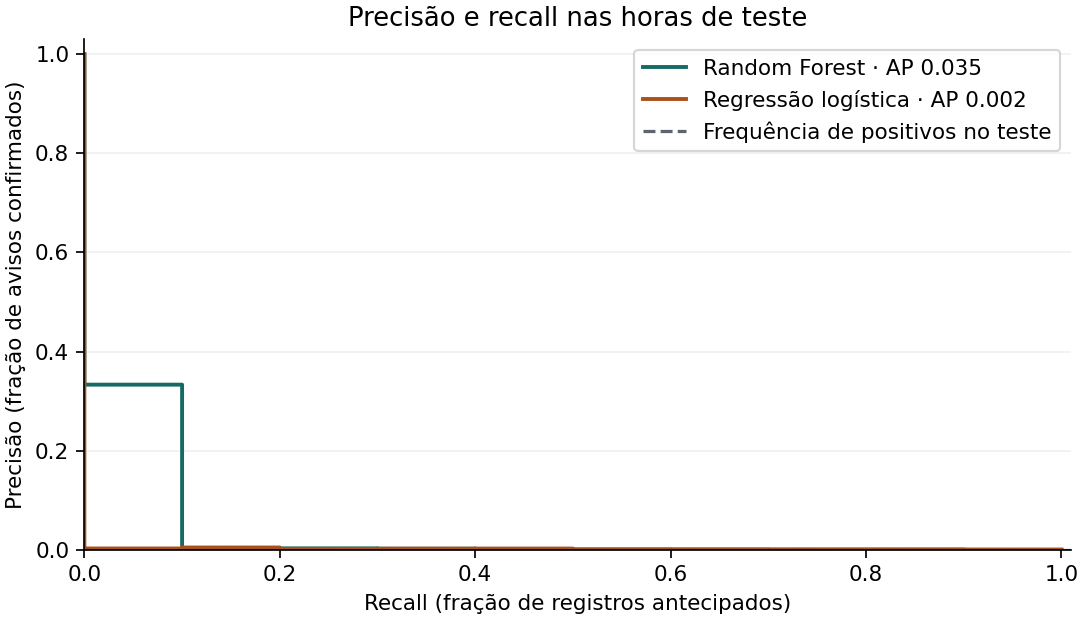

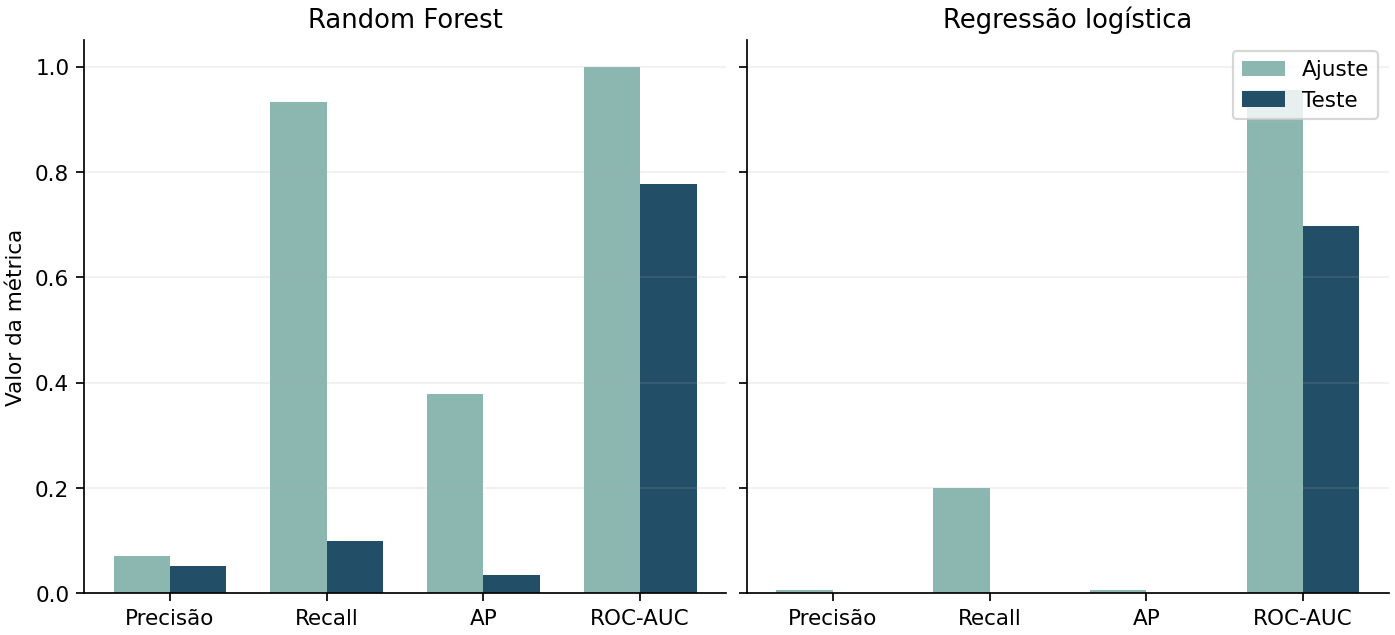

In [7]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
cores = {"Random Forest": "#156a66", "Regressão logística": "#aa501b"}
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for nome in modelos:
    prec, rec, _ = precision_recall_curve(teste[alvo], probabilidades[nome]["Teste"])
    ap = average_precision_score(teste[alvo], probabilidades[nome]["Teste"])
    ax.step(rec, prec, where="post", color=cores[nome], label=f"{nome} · AP {ap:.3f}", linewidth=1.8)
ax.axhline(teste[alvo].mean(), color="#5b6470", linestyle="--", label="Frequência de positivos no teste")
ax.set(xlabel="Recall (fração de registros antecipados)", ylabel="Precisão (fração de avisos confirmados)",
       xlim=(0, 1.01), ylim=(0, 1.03), title="Precisão e recall nas horas de teste")
ax.grid(axis="y", alpha=0.18)
ax.legend()
fig.savefig(saida / "curva_precisao_recall.png", dpi=155)
plt.close(fig)
display(Image(filename=str(saida / "curva_precisao_recall.png"), width=720))

fig, eixos = plt.subplots(1, 2, figsize=(9, 4.1), sharey=True, layout="constrained")
campos = ["precisao", "recall", "ap", "roc_auc"]
x = np.arange(len(campos))
for ax, nome in zip(eixos, modelos):
    m = metricas.loc[metricas.modelo == nome].set_index("periodo")
    ax.bar(x - 0.18, m.loc["Ajuste", campos].astype(float), width=0.36, label="Ajuste", color="#8bb7b0")
    ax.bar(x + 0.18, m.loc["Teste", campos].astype(float), width=0.36, label="Teste", color="#224e67")
    ax.set_xticks(x, ["Precisão", "Recall", "AP", "ROC-AUC"])
    ax.set_title(nome)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.18)
eixos[0].set_ylabel("Valor da métrica")
eixos[1].legend(loc="upper right")
fig.savefig(saida / "ajuste_e_teste.png", dpi=155)
plt.close(fig)
display(Image(filename=str(saida / "ajuste_e_teste.png"), width=850))

## 6. Previsões auditáveis e leitura para o cidadão

A tabela de teste preserva todas as horas elegíveis. Inclui a emissão, o fim da janela, o local, o alvo observado e as estimativas dos dois métodos. A coluna de aviso aplica o limiar já escolhido em 2024. Um roteador poderia consultar a estimativa e a validade junto com a última confirmação local. Um aviso tem custo de desvio e uma falha pode expor o usuário à água. O arquivo de modelo inclui a floresta, o calibrador e o limiar definidos antes do teste. O [comando de demonstração](prever.py) usa esse arquivo para produzir a mesma estimativa individual em JSON.

In [8]:
previsoes = teste[["hora_local", "trecho_id", alvo]].copy()
previsoes.insert(1, "validade_ate", previsoes.hora_local + horizonte)
for nome, sufixo in [("Random Forest", "rf"), ("Regressão logística", "logistica")]:
    p = probabilidades[nome]["Teste"]
    previsoes[f"prob_{sufixo}"] = p
    previsoes[f"aviso_{sufixo}"] = (p >= limiares[nome]).astype(int)
previsoes.to_csv(saida / "previsoes_teste.csv.gz", index=False,
                 compression={"method": "gzip", "mtime": 0, "compresslevel": 6})
display(previsoes.head(8))

rf = metricas.loc[metricas.modelo == "Random Forest"].set_index("periodo")
logistica = metricas.loc[metricas.modelo == "Regressão logística"].set_index("periodo")
t = rf.loc["Teste"]
l = logistica.loc["Teste"]
texto = (
    f"**No teste, a floresta antecipou {int(t.tp)} das {int(t.positivas)} janelas positivas** "
    f"e deixou passar {int(t.fn)}. Dos {int(t.avisos)} avisos, {int(t.fp)} ficaram sem início de "
    f"registro naquela janela. A regressão logística antecipou {int(l.tp)} e gerou {int(l.fp)} "
    f"falsos positivos. A AP da floresta passou de {rf.loc['Ajuste', 'ap']:.3f} no ajuste para "
    f"{t.ap:.3f} no teste, diante de prevalência de {t.prevalencia:.3%} no teste. "
    f"A AP da logística no teste foi {l.ap:.3f}. O Brier da floresta foi {t.brier:.6f}, "
    f"comparado a {t.brier_referencia:.6f} para a taxa constante aprendida no ajuste."
)
display(Markdown(texto))

,hora_local,validade_ate,trecho_id,alagou_proxima_hora,prob_rf,aviso_rf,prob_logistica,aviso_logistica
46528,2025-01-01 00:00:00,2025-01-01 01:00:00,RS01,0,9.250758e-10,0,0.000596,0
46529,2025-01-01 00:00:00,2025-01-01 01:00:00,RS02,0,1.080202e-04,0,0.000790,0
46530,2025-01-01 00:00:00,2025-01-01 01:00:00,RS03,0,9.250758e-10,0,0.000023,0
46531,2025-01-01 00:00:00,2025-01-01 01:00:00,RS04,0,1.080202e-04,0,0.000458,0
46532,2025-01-01 01:00:00,2025-01-01 02:00:00,RS01,0,9.250758e-10,0,0.000535,0
46533,2025-01-01 01:00:00,2025-01-01 02:00:00,RS02,0,1.080202e-04,0,0.000710,0
46534,2025-01-01 01:00:00,2025-01-01 02:00:00,RS03,0,9.250758e-10,0,0.000023,0
46535,2025-01-01 01:00:00,2025-01-01 02:00:00,RS04,0,1.080202e-04,0,0.000412,0


**No teste, a floresta antecipou 1 das 10 janelas positivas** e deixou passar 9. Dos 19 avisos, 18 ficaram sem início de registro naquela janela. A regressão logística antecipou 0 e gerou 224 falsos positivos. A AP da floresta passou de 0.379 no ajuste para 0.035 no teste, diante de prevalência de 0.031% no teste. A AP da logística no teste foi 0.002. O Brier da floresta foi 0.000312, comparado a 0.000313 para a taxa constante aprendida no ajuste.

A comparação ajuste–teste ajuda a avaliar sobreajuste. Também mudam o período, os temporais e os registros disponíveis. Cada tempestade pode atingir vários locais, então as linhas de uma mesma chuva são correlacionadas. A precisão observada depende da frequência de registros nestes cruzamentos.

Para o cidadão, a saída é um sinal complementar de atenção para uma janela de **uma hora**. Um trajeto com escore baixo ainda pode estar alagado. O produto deve deixar visíveis o horário dos dados, a cobertura e as confirmações do CGE. O experimento cobre os cruzamentos estudados, depende da chuva observada pela estação e não mede a profundidade da água, a condição de cada modal ou a segurança da rota inteira.

## 7. Chuva local e validação temporal

Em 2025, a floresta original antecipou 1 de 10 inícios avaliáveis. A nova pergunta é se medir a chuva mais perto de cada cruzamento melhora o aviso. A A701 (Mirante) continua mais próxima do RS01. Para os outros três locais usamos Interlagos (A771). No RS02, a distância passa de 21,86 km para 5,03 km. O experimento inclui ainda a precipitação máxima das duas estações e testa, como alternativa, a presença de chuva no METAR de Congonhas.

O estudo inicial já havia examinado 2025. Desta vez usamos 2023–2025 para desenvolvimento e reservamos 2026. O alvo, os quatro cruzamentos e o horizonte continuam iguais. As etapas abaixo recompõem a seleção e a avaliação nos períodos definidos antes do teste. [Implementação](estudo_local.py) · [Interlagos](dados/chuva_interlagos/README.md) · [Congonhas](dados/chuva_local/README.md)

Comparamos, para cada uma das quatro combinações de fontes, 12 configurações de floresta (32/64 árvores, profundidade 3/5/8 e 8/32 exemplos por folha) e uma regressão logística. Em quatro blocos semestrais, cada treinamento usa apenas as horas anteriores e exclui a janela que atinge a fronteira. O histórico por trecho termina na véspera. Usamos todos os positivos e até 20 mil negativos sorteados com semente fixa em cada ajuste. A calibração, a validação e o teste usam todos os exemplos com cobertura, nas proporções observadas.

O treino abaixo reproduz a busca em uma pasta temporária. A avaliação seguinte carrega o pacote oficial congelado antes da abertura do teste de 2026.

In [9]:
from pathlib import Path
from tempfile import TemporaryDirectory

from estudo_local import SAIDA, avaliar, avaliar_amostra_treino, grafico_comparacao, treinar

with TemporaryDirectory(prefix="rota-seca-treino-") as pasta_ajuste:
    grade_local, ficha = treinar(Path(pasta_ajuste))
display(grade_local.groupby("configuracao", sort=False).head(1).reset_index(drop=True))
print(f"Emissões no desenvolvimento: {ficha['linhas_ajuste']} | positivas: {ficha['positivos_ajuste']}")
print(f"Emissões de validação temporal: {ficha['linhas_validacao']} | positivas: {ficha['positivos_validacao']}")
print("Modelo local selecionado e congelado:", ficha["local"])

Emissões possíveis: 105212; sem janela de chuva: 10728; inícios positivos excluídos: 4.


,configuracao,arvores,profundidade,folha,ap,ap_bloco_1,ap_bloco_2,ap_bloco_3,ap_bloco_4
0,Duas estações,32,5,8,0.043533,0.294097,0.053300,0.006734,0.014333
1,Duas estações + Congonhas,32,5,32,0.033770,0.216495,0.036042,0.003894,0.023811
2,Mais próxima,32,8,8,0.027468,0.170621,0.020830,0.006962,0.019950
3,Mirante,32,5,32,0.007907,0.007401,0.027324,0.002227,0.027731


Emissões no desenvolvimento: 90640 | positivas: 60
Emissões de validação temporal: 63984 | positivas: 23
Modelo local selecionado e congelado: {'configuracao': 'Duas estações', 'metodo': 'Random Forest', 'parametros': (32, 5, 8), 'limiar': 0.031107915635717985}


## 8. Teste externo e limites do alerta

A seleção maximiza a precisão média (AP) nas previsões temporais fora do ajuste. Os escores dessas previsões permitem calibrar as probabilidades e escolher um limiar que maximize F2 com até 25 avisos por 10 mil emissões de validação. A taxa observada em um período novo pode mudar. O comparativo a seguir usa os mesmos locais e horários em 2026. A floresta original conserva o treinamento e o limiar da primeira edição. O *controle* usa os mesmos parâmetros do candidato local, mas recebe apenas a chuva da A701. O modelo *mirante* teve sua própria seleção com A701.

Emissões possíveis: 105212; sem janela de chuva: 10728; inícios positivos excluídos: 4.


,modelo,periodo,linhas,positivos,tp,fp,fn,precisao,recall,ap,roc_auc,brier
0,local,Treino efetivo,20060,60,15,28,45,0.348837,0.250000,0.240910,0.987622,0.002865
1,local,Validação temporal,63984,23,5,63,18,0.073529,0.217391,0.043533,0.969289,0.000354
2,local,Desenvolvimento (reajuste),90640,60,15,133,45,0.101351,0.250000,0.066900,0.987708,0.000647
3,local,Teste 2026,23232,9,0,40,9,0.000000,0.000000,0.018120,0.987070,0.000398


,modelo,periodo,linhas,positivos,tp,fp,fn,precisao,recall,ap,roc_auc,brier
0,local,Teste 2026,23232,9,0,40,9,0.0,0.0,0.018120,0.987070,0.000398
1,mirante,Teste 2026,23232,9,0,74,9,0.0,0.0,0.004627,0.931840,0.000388
2,controle,Teste 2026,23232,9,0,55,9,0.0,0.0,0.003744,0.931569,0.000387
3,original,Teste 2026,23232,9,0,6,9,0.0,0.0,0.007485,0.788311,0.000387


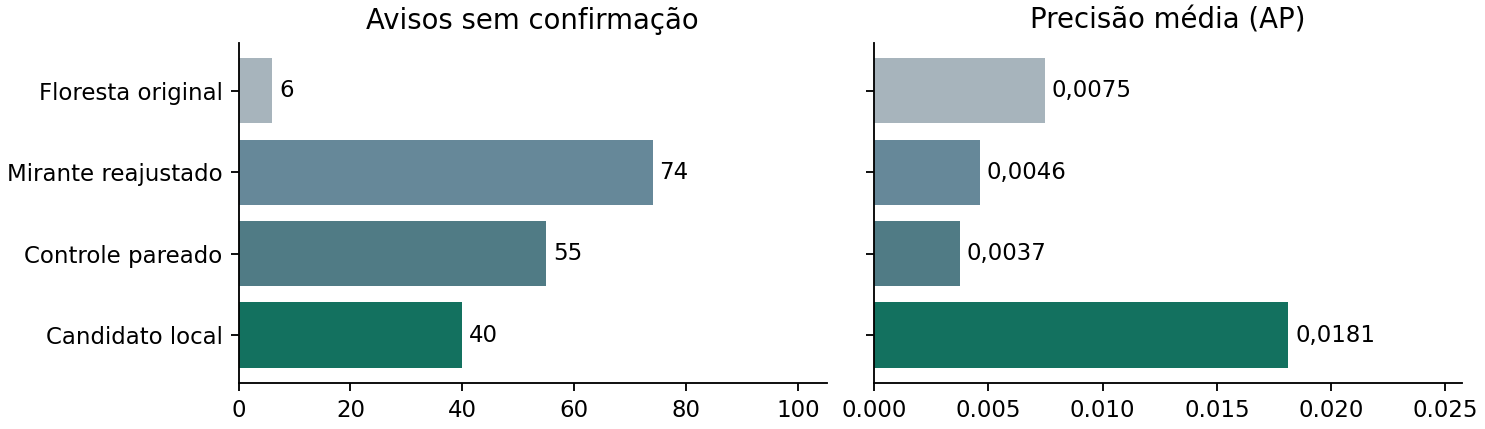

In [10]:
treino_efetivo = avaliar_amostra_treino()
teste_externo = avaliar()
grafico_comparacao(teste_externo)
desenvolvimento = pd.read_csv(SAIDA / "metricas_desenvolvimento.csv")
comparacao = pd.concat([treino_efetivo, desenvolvimento, teste_externo], ignore_index=True)
campos = ["modelo", "periodo", "linhas", "positivos", "tp", "fp", "fn", "precisao", "recall", "ap", "roc_auc", "brier"]
display(comparacao.loc[comparacao.modelo.eq("local"), campos].round(6).reset_index(drop=True))
display(teste_externo[campos].round(6))
display(Image(filename=str(SAIDA / "comparacao_2026.png"), width=760))

### Precisão e recall do candidato com duas estações

A precisão mostra quantos avisos coincidiram com um novo registro, e o recall mostra quantos inícios foram antecipados. O treino efetivo contém as 20.060 linhas usadas no ajuste final: 60 inícios e 20.000 negativos sorteados. Essa proporção de eventos eleva a precisão observada na amostra de treino. A tabela acima também apresenta as 90.640 linhas do desenvolvimento completo após o reajuste, com a frequência original de registros. A validação reúne quatro semestres de previsões fora do ajuste de cada floresta e serviu para definir o limiar. No teste de 2026, o modelo e o limiar já estavam congelados.

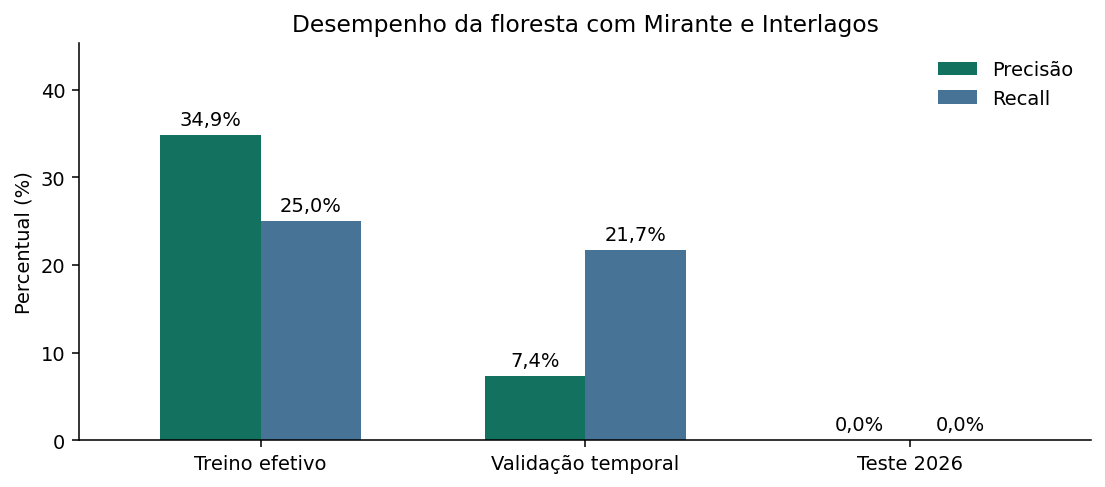

In [11]:
from io import BytesIO

periodos = ["Treino efetivo", "Validação temporal", "Teste 2026"]
por_periodo = comparacao.loc[comparacao.modelo.eq("local")].set_index("periodo").loc[periodos]
percentuais = por_periodo[["precisao", "recall"]].mul(100)
percentuais.columns = ["Precisão", "Recall"]

ax = percentuais.plot.bar(figsize=(8, 3.6), rot=0, color=["#13715f", "#477397"], width=0.62)
ax.set(xlabel="", ylabel="Percentual (%)", ylim=(0, max(5, percentuais.max().max() * 1.3)))
ax.set_title("Desempenho da floresta com Mirante e Interlagos")
ax.legend(frameon=False)
for barras in ax.containers:
    rotulos = [f"{barra.get_height():.1f}%".replace(".", ",") for barra in barras]
    ax.bar_label(barras, labels=rotulos, padding=3)
plt.tight_layout()
with BytesIO() as imagem:
    ax.figure.savefig(imagem, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=imagem.getvalue()))
plt.close(ax.figure)

## 9. O que mudou para o cidadão

A amostra pareada de 2026 contém 9 inícios em 23.232 emissões. O candidato com duas estações emitiu 40 avisos, todos sem um novo início registrado naquela hora. A floresta original emitiu seis e também perdeu os nove registros. A precisão média subiu de 0,0075 na versão original para 0,0181 no candidato local. O melhor posicionamento dos registros na ordenação dos escores não se converteu em acertos com o limiar de 3,111% definido antes do teste.

A versão local teve recall de 25% no conjunto de desenvolvimento pontuado após o reajuste, 21,7% nas previsões de validação usadas para escolher o limiar e 0% no teste externo. Essa queda é compatível com sobreajuste e instabilidade em amostras com poucos eventos. O teste abrange nove meses e os cruzamentos foram escolhidos por recorrência histórica. Um alerta pode servir à demonstração de como o sistema processa as medições; recomendar travessias e desvios exigiria desempenho consistente em novos casos. As previsões auditáveis estão em [previsoes_2026.csv.gz](resultados/otimizacao/previsoes_2026.csv.gz).